# Atividade Prática: Manipulação e Decisões de Visualização de Dados das IFES

**Dupla:** Nathan Mateus de Lima e Vítor Oliveira Amorim  
**Professora:** Carolina Ribeiro Xavier  
**Disciplina:** Tecnologias para Data Science  

### 1.  Carregar, Preparar e Explorar os Dados

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style='whitegrid')

In [18]:
df = pd.read_csv("dados_investimento_e_vagas_ifes.csv")
df.head()

,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
0,1996,32.1,0.02,342100,26800,43100,8200
1,1997,31.8,0.02,351400,27100,42800,8600
2,1998,30.5,0.03,362900,27400,42100,9100
3,1999,29.8,0.03,375200,27600,41500,9800
4,2000,31.2,0.04,391800,28100,41900,10400


In [19]:
print(df.describe())

               ano  investimento_total_ifes_bilhoes_brl  \
count    31.000000                            31.000000   
mean   2011.000000                            53.019355   
std       9.092121                            15.830802   
min    1996.000000                            29.800000   
25%    2003.500000                            34.350000   
50%    2011.000000                            54.100000   
75%    2018.500000                            65.950000   
max    2026.000000                            76.500000   

       investimento_assistencia_estudantil_bilhoes_brl  num_vagas_estudantes  \
count                                        31.000000          3.100000e+01   
mean                                          0.693548          8.967581e+05   
std                                           0.534749          4.008678e+05   
min                                           0.020000          3.421000e+05   
25%                                           0.070000          4.65

### Evolução Temporal e Ajuste de Escalas

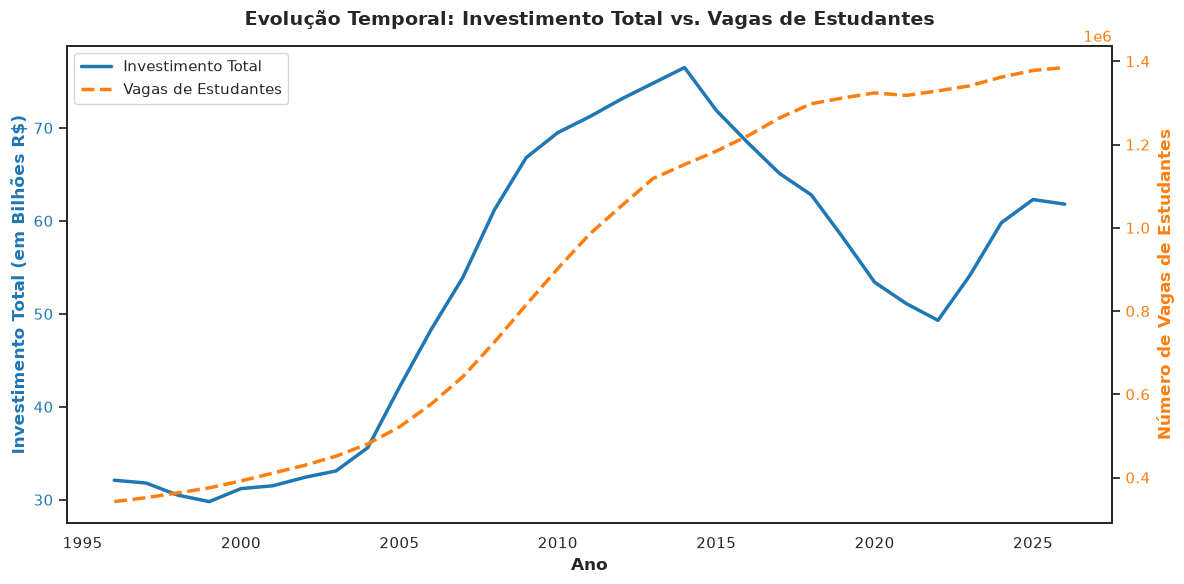

In [42]:
df_agrupado = (
    df.groupby('ano')
    .agg(
        {
            'investimento_total_ifes_bilhoes_brl': 'sum',
            'num_vagas_estudantes': 'sum',
        }
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Ano', fontsize=12, fontweight='bold')
ax1.set_ylabel(
    'Investimento Total (em Bilhões R$)',
    color=color,
    fontsize=12,
    fontweight='bold',
)
line1 = ax1.plot(
    df_agrupado['ano'],
    df_agrupado['investimento_total_ifes_bilhoes_brl'],
    color=color,
    linewidth=2.5,
    label='Investimento Total',
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel(
    'Número de Vagas de Estudantes',
    color=color,
    fontsize=12,
    fontweight='bold',
)
line2 = ax2.plot(
    df_agrupado['ano'],
    df_agrupado['num_vagas_estudantes'],
    color=color,
    linewidth=2.5,
    linestyle='--',
    label='Vagas de Estudantes',
)
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.title(
    'Evolução Temporal: Investimento Total vs. Vagas de Estudantes',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
fig.tight_layout()
plt.show()

### Análise de Proporção de Força de Trabalho (Docentes vs. TAEs)

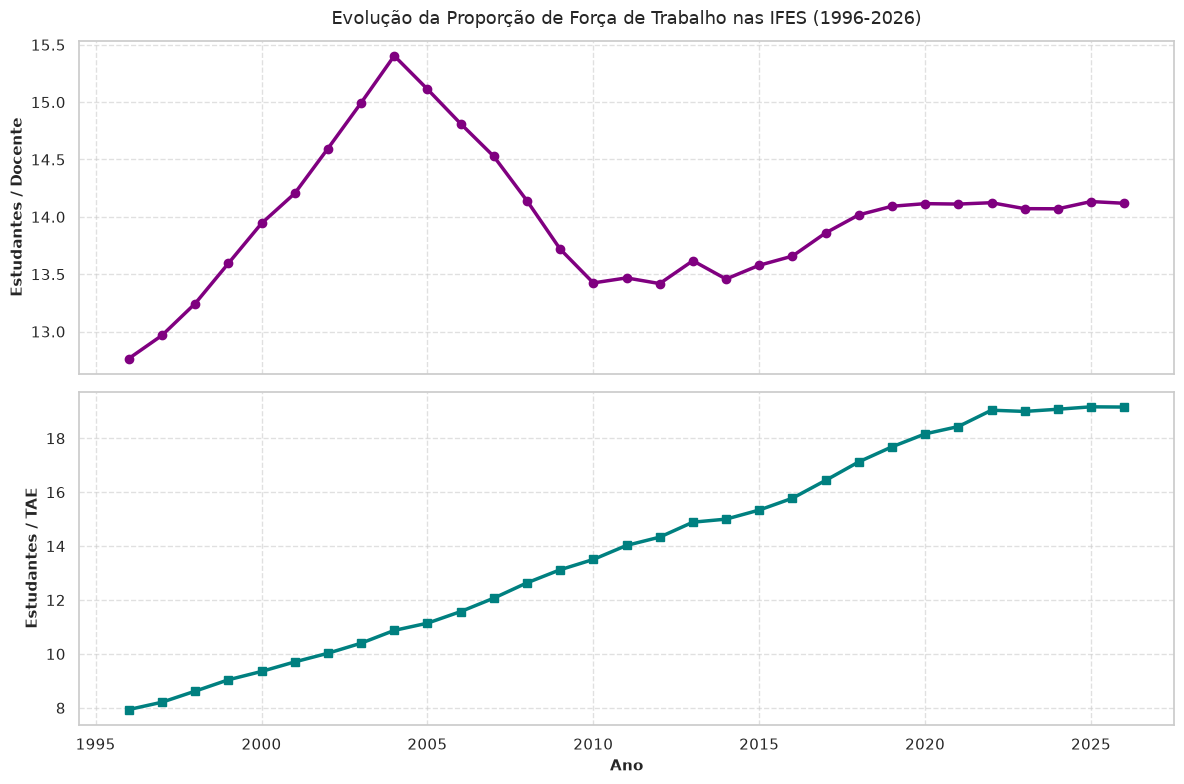

In [21]:
df['prop_estudante_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['prop_estudante_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(df['ano'], df['prop_estudante_docente'], color='purple', linewidth=2.5, marker='o')
ax1.set_ylabel('Estudantes / Docente', fontsize=11, fontweight='bold')
ax1.set_title('Evolução da Proporção de Força de Trabalho nas IFES (1996-2026)', fontsize=13, pad=12)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(df['ano'], df['prop_estudante_tae'], color='teal', linewidth=2.5, marker='s')
ax2.set_ylabel('Estudantes / TAE', fontsize=11, fontweight='bold')
ax2.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

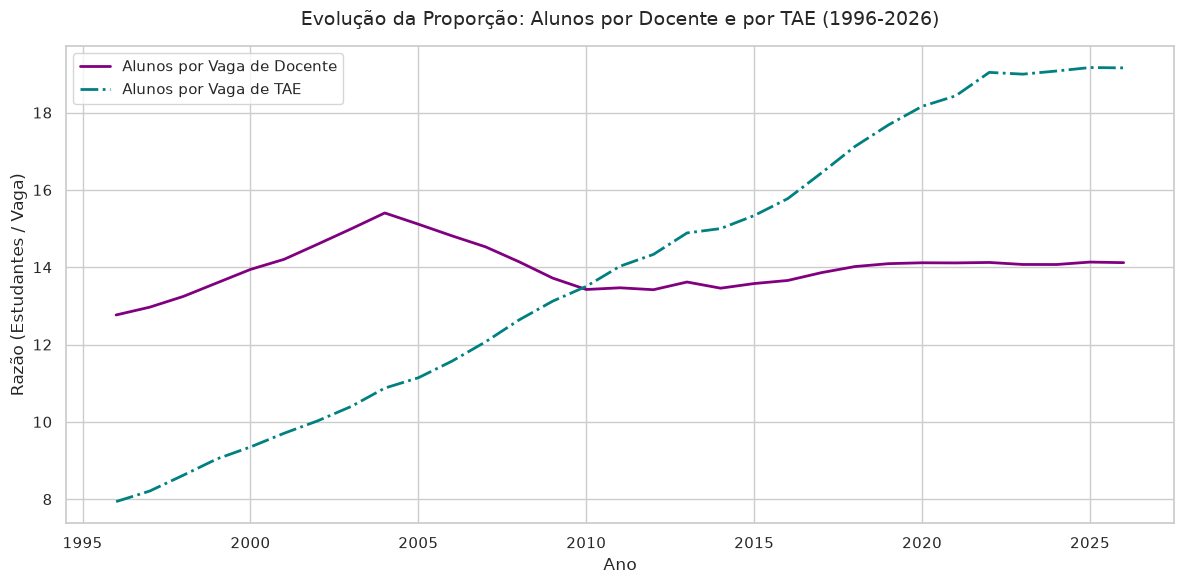

In [22]:
df['prop_estudante_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['prop_estudante_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

plt.figure(figsize=(12, 6))
plt.plot(
    df['ano'],
    df['prop_estudante_docente'],
    label='Alunos por Vaga de Docente',
    linewidth=2,
    color='purple',
)
plt.plot(
    df['ano'],
    df['prop_estudante_tae'],
    label='Alunos por Vaga de TAE',
    linewidth=2,
    color='teal',
    linestyle='-.',
)

plt.title(
    'Evolução da Proporção: Alunos por Docente e por TAE (1996-2026)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Razão (Estudantes / Vaga)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Correlação entre Fatores e Desempenho Orçamentário (Método agg):

In [38]:
def categorizar_periodo(ano):
  if ano <= 2002:
    return '1996-2002'
  elif 2003 <= ano <= 2010:
    return '2003-2010'
  elif 2011 <= ano <= 2016:
    return '2011-2016'
  elif 2017 <= ano <= 2022:
    return '2017-2022'
  else:
    return '2023+'

df['periodo'] = df['ano'].apply(categorizar_periodo)

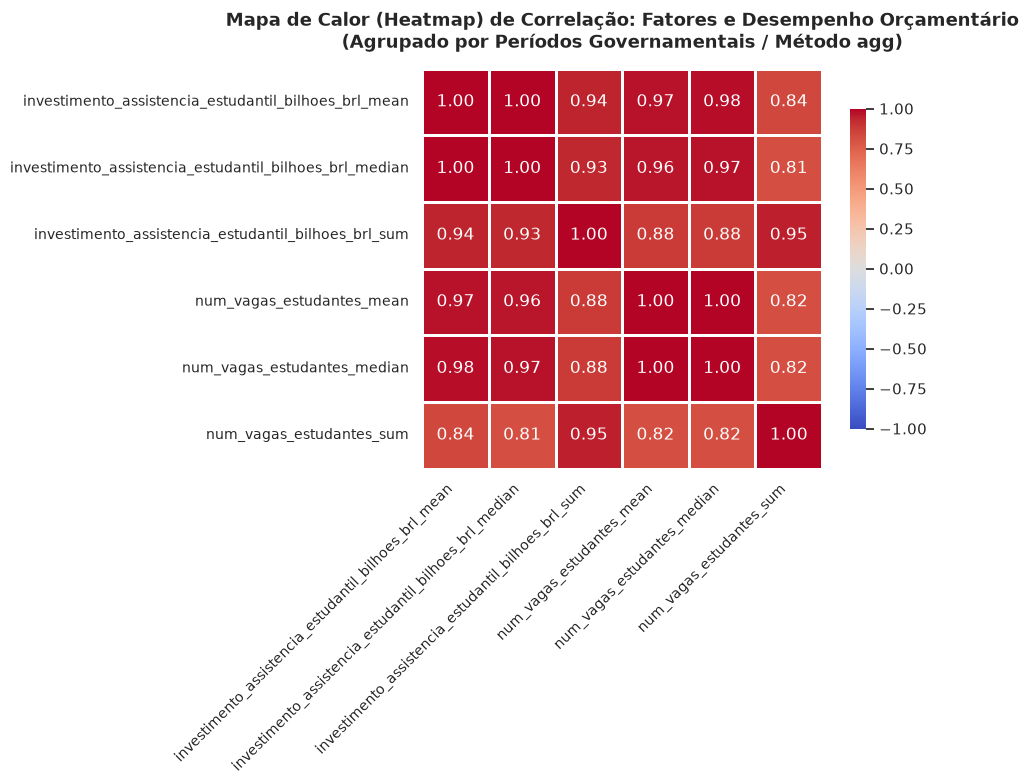

In [39]:
dados_agrupados = (
    df.groupby('periodo')
    .agg({
        'investimento_assistencia_estudantil_bilhoes_brl': [
            'mean',
            'median',
            'sum',
        ],
        'num_vagas_estudantes': [
            'mean',
            'median',
            'sum',
        ],
    })
    .reset_index()
)

dados_agrupados.columns = [
    '_'.join(col).strip('_') for col in dados_agrupados.columns.values
]

matriz_correlacao = dados_agrupados.drop(
    columns=['periodo'], errors='ignore'
).corr()

plt.figure(figsize=(10, 8))
sns.set_theme(style='white')

ax = sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={'shrink': 0.8},
)

plt.title(
    'Mapa de Calor (Heatmap) de Correlação: Fatores e Desempenho Orçamentário'
    '\n(Agrupado por Períodos Governamentais / Método agg)',
    fontsize=13,
    pad=15,
    fontweight='bold',
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Exibição do gráfico
plt.show()

          investimento_assistencia_estudantil_bilhoes_brl               \
                                                     mean median   sum   
periodo                                                                  
1996-2002                                        0.032857  0.030  0.23   
2003-2010                                        0.312500  0.215  2.50   
2011-2016                                        1.190000  1.245  7.14   
2017-2022                                        1.145000  1.165  6.87   
2023+                                            1.190000  1.215  4.76   

          num_vagas_estudantes                      
                          mean     median      sum  
periodo                                             
1996-2002         3.804286e+05   375200.0  2663000  
2003-2010         6.392500e+05   609150.0  5114000  
2011-2016         1.118583e+06  1135000.0  6711500  
2017-2022         1.307500e+06  1315000.0  7845000  
2023+             1.366500e+06  1370

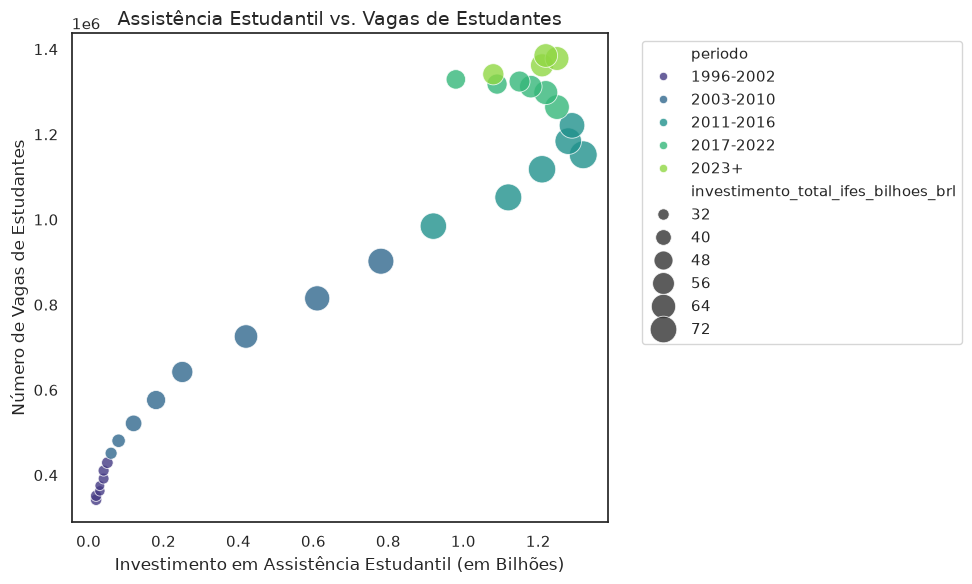

In [40]:
resumo_agg = df.groupby('periodo').agg({
    'investimento_assistencia_estudantil_bilhoes_brl': ['mean', 'median', 'sum'],
    'num_vagas_estudantes': ['mean', 'median', 'sum'],
})
print(resumo_agg)

# Bubble Chart com Seaborn
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='investimento_assistencia_estudantil_bilhoes_brl',
    y='num_vagas_estudantes',
    size='investimento_total_ifes_bilhoes_brl',
    hue='periodo',
    palette='viridis',
    sizes=(50, 400),
    alpha=0.8,
)
plt.title(
    'Assistência Estudantil vs. Vagas de Estudantes',
    fontsize=14,
)
plt.xlabel(
    'Investimento em Assistência Estudantil (em Bilhões)', fontsize=12
)
plt.ylabel('Número de Vagas de Estudantes', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Filtragem Condicional de Anos Críticos (filter)

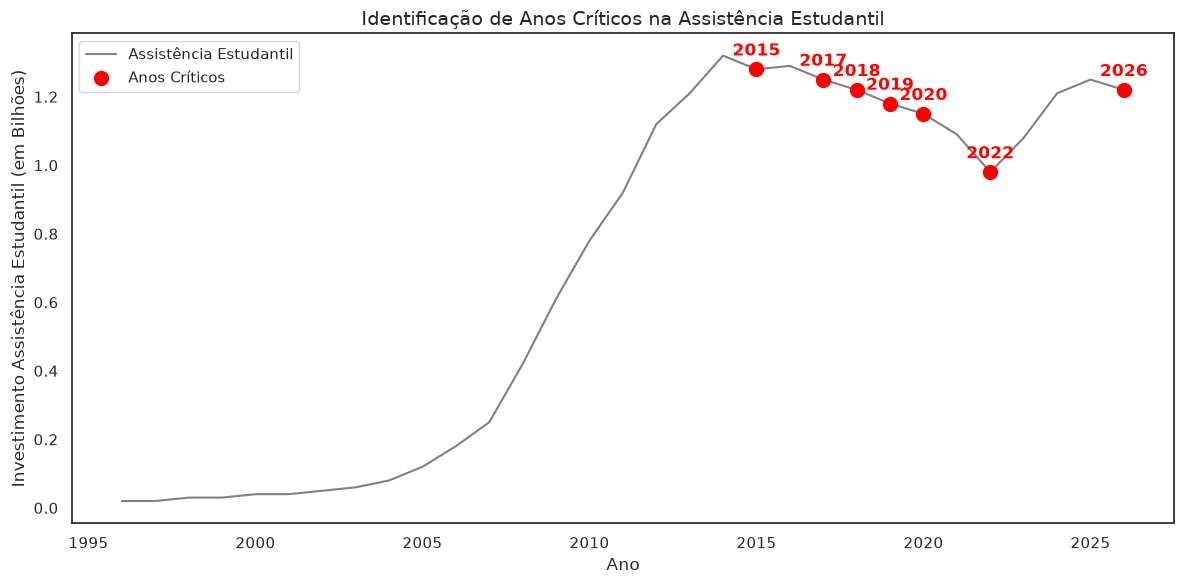

In [41]:
df['dif_assistencia'] = df['investimento_assistencia_estudantil_bilhoes_brl'].diff()
df['dif_vagas'] = df['num_vagas_estudantes'].diff()

anos_criticos = df[
    (df['dif_assistencia'] < 0) & (df['dif_vagas'] > 0)
]['ano'].tolist()

plt.figure(figsize=(12, 6))
plt.plot(
    df['ano'],
    df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='gray',
    linewidth=1.5,
    label='Assistência Estudantil',
)

criticos_df = df[df['ano'].isin(anos_criticos)]
plt.scatter(
    criticos_df['ano'],
    criticos_df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='red',
    s=100,
    zorder=5,
    label='Anos Críticos',
)

for ano in anos_criticos:
  y_val = df.loc[df['ano'] == ano, 'investimento_assistencia_estudantil_bilhoes_brl'].values[
      0
  ]
  plt.annotate(
      f'{ano}',
      (ano, y_val),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontweight='bold',
      color='red',
  )

plt.title('Identificação de Anos Críticos na Assistência Estudantil', fontsize=14)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Investimento Assistência Estudantil (em Bilhões)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()